## 1. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Go To Your Project Folder

Change `PROJECT_DIR` if you saved the folder somewhere else in Drive.

In [2]:
import os

PROJECT_DIR = '/content/drive/MyDrive/AI emotion detection using audio and text'
os.chdir(PROJECT_DIR)
print('Current folder:', os.getcwd())
!ls

Current folder: /content/drive/MyDrive/AI emotion detection using audio and text
app_colab.py  config.yaml  models     pyproject.toml  reports		scripts
app.py	      data	   notebooks  README.md       requirements.txt	src


## 3. Install Dependencies

In [3]:
%cd "/content/drive/MyDrive/AI emotion detection using audio and text"
!pip install -q -r requirements.txt

/content


## 4. Check Imports

In [4]:
import sys
sys.path.insert(0, 'src')

from emotion_detection.config import load_config
from emotion_detection.text import clean_text

config = load_config('config.yaml')
print(config['project']['name'])
print(clean_text('I am very HAPPY today!!!'))

AI Emotion Detection Using Audio and Text
i am very happy today!!!


## 5. Prepare A Dataset

Your real dataset should be a CSV with these columns:

audio_path,text,emotion

For a quick smoke test, this cell creates a small text-only dataset. Use it only to verify the pipeline, not for real accuracy.

In [5]:
import pandas as pd
from pathlib import Path

Path('data/processed').mkdir(parents=True, exist_ok=True)

demo_rows = [
    {'audio_path': '', 'text': 'I am so happy and excited today', 'emotion': 'happy'},
    {'audio_path': '', 'text': 'This is wonderful and I feel great', 'emotion': 'happy'},
    {'audio_path': '', 'text': 'I am smiling because this is amazing', 'emotion': 'happy'},
    {'audio_path': '', 'text': 'I feel very sad and alone', 'emotion': 'sad'},
    {'audio_path': '', 'text': 'This makes me want to cry', 'emotion': 'sad'},
    {'audio_path': '', 'text': 'My heart feels heavy and low', 'emotion': 'sad'},
    {'audio_path': '', 'text': 'I am furious about what happened', 'emotion': 'angry'},
    {'audio_path': '', 'text': 'This is unacceptable and I am angry', 'emotion': 'angry'},
    {'audio_path': '', 'text': 'I hate this situation so much', 'emotion': 'angry'},
    {'audio_path': '', 'text': 'I am calm and relaxed now', 'emotion': 'calm'},
    {'audio_path': '', 'text': 'Everything feels peaceful and steady', 'emotion': 'calm'},
    {'audio_path': '', 'text': 'My breathing is slow and I feel quiet', 'emotion': 'calm'},
]

demo_path = 'data/processed/colab_demo_text.csv'
pd.DataFrame(demo_rows).to_csv(demo_path, index=False)
pd.read_csv(demo_path)

,audio_path,text,emotion
0,NaN,I am so happy and excited today,happy
1,NaN,This is wonderful and I feel great,happy
2,NaN,I am smiling because this is amazing,happy
3,NaN,I feel very sad and alone,sad
4,NaN,This makes me want to cry,sad
5,NaN,My heart feels heavy and low,sad
6,NaN,I am furious about what happened,angry
7,NaN,This is unacceptable and I am angry,angry
8,NaN,I hate this situation so much,angry
9,NaN,I am calm and relaxed now,calm


## 6. Train A Text Model

This trains quickly and proves everything is connected.

In [6]:
!python scripts/train.py --data data/processed/colab_demo_text.csv --mode text --output models/colab_text_model.joblib

              precision    recall  f1-score   support

       angry       0.00      0.00      0.00       0.0
        calm       0.00      0.00      0.00       2.0
       happy       0.00      0.00      0.00       1.0
         sad       0.00      0.00      0.00       0.0

    accuracy                           0.00       3.0
   macro avg       0.00      0.00      0.00       3.0
weighted avg       0.00      0.00      0.00       3.0

Saved model to models/colab_text_model.joblib


## 7. Predict From Text

In [7]:
!python scripts/predict.py --model models/colab_text_model.joblib --text "I am feeling peaceful and relaxed"

{
  "emotion": "angry",
  "probabilities": {
    "angry": 0.30219998700092704,
    "sad": 0.25920531172371414,
    "happy": 0.24816716158514587,
    "calm": 0.19042753969021287
  }
}


## 8. Download RAVDESS Audio Dataset From Kaggle

RAVDESS is an audio emotion dataset. It also has two fixed spoken statements, so this notebook can create both an audio-only CSV and an audio+text CSV.

In [8]:
import os

os.environ['KAGGLE_API_TOKEN'] = 'KGAT_170b817481c8b72715e026be3c1a3320'

!pip install -q kaggle
!kaggle datasets download -d uwrfkaggler/ravdess-emotional-speech-audio -p data/raw/ravdess --unzip

Dataset URL: https://www.kaggle.com/datasets/uwrfkaggler/ravdess-emotional-speech-audio
License(s): CC-BY-NC-SA-4.0
100% 429M/429M [00:19<00:00, 23.0MB/s]

User cancelled operation


In [9]:
!rm -rf data/raw/ravdess
!mkdir -p data/raw/ravdess
!kaggle datasets download -d uwrfkaggler/ravdess-emotional-speech-audio -p data/raw/ravdess --unzip --force

Dataset URL: https://www.kaggle.com/datasets/uwrfkaggler/ravdess-emotional-speech-audio
License(s): CC-BY-NC-SA-4.0
100% 429M/429M [00:20<00:00, 22.0MB/s]



## 9. Create Audio-Only And Audio+Text CSV Files

The audio-only CSV leaves text blank. The multimodal CSV includes the spoken sentence from the RAVDESS filename.

In [10]:
!python scripts/prepare_ravdess.py --input data/raw/ravdess --output data/processed/ravdess_audio_dataset.csv
!python scripts/prepare_ravdess.py --input data/raw/ravdess --output data/processed/ravdess_multimodal_dataset.csv --include-text

import pandas as pd
pd.read_csv('data/processed/ravdess_multimodal_dataset.csv').head()

Saved 2880 rows to data/processed/ravdess_audio_dataset.csv
emotion
angry        384
calm         384
disgust      384
fearful      384
happy        384
neutral      192
sad          384
surprised    384
Name: count, dtype: int64
Saved 2880 rows to data/processed/ravdess_multimodal_dataset.csv
emotion
angry        384
calm         384
disgust      384
fearful      384
happy        384
neutral      192
sad          384
surprised    384
Name: count, dtype: int64


,audio_path,text,emotion
0,/content/drive/MyDrive/AI emotion detection us...,Kids are talking by the door.,neutral
1,/content/drive/MyDrive/AI emotion detection us...,Kids are talking by the door.,neutral
2,/content/drive/MyDrive/AI emotion detection us...,Dogs are sitting by the door.,neutral
3,/content/drive/MyDrive/AI emotion detection us...,Dogs are sitting by the door.,neutral
4,/content/drive/MyDrive/AI emotion detection us...,Kids are talking by the door.,calm


## 10. Train Audio-Only Model

In [11]:
!python scripts/train.py --data data/processed/ravdess_audio_dataset.csv --mode audio --output models/ravdess_audio_model.joblib

              precision    recall  f1-score   support

       angry       0.94      0.99      0.96        76
        calm       0.96      0.95      0.95        77
     disgust       0.98      0.83      0.90        77
     fearful       0.97      0.95      0.96        77
       happy       0.86      0.87      0.86        77
     neutral       0.88      1.00      0.94        38
         sad       0.84      0.87      0.85        77
   surprised       0.92      0.95      0.94        77

    accuracy                           0.92       576
   macro avg       0.92      0.93      0.92       576
weighted avg       0.92      0.92      0.92       576

Saved model to models/ravdess_audio_model.joblib


## 11. Train Audio + Text Model

In [12]:
!python scripts/train.py --data data/processed/ravdess_multimodal_dataset.csv --mode multimodal --output models/ravdess_multimodal_model.joblib

              precision    recall  f1-score   support

       angry       0.93      0.99      0.96        76
        calm       0.96      0.96      0.96        77
     disgust       1.00      0.82      0.90        77
     fearful       0.97      0.95      0.96        77
       happy       0.86      0.87      0.86        77
     neutral       0.88      1.00      0.94        38
         sad       0.84      0.87      0.85        77
   surprised       0.92      0.95      0.94        77

    accuracy                           0.92       576
   macro avg       0.92      0.93      0.92       576
weighted avg       0.92      0.92      0.92       576

Saved model to models/ravdess_multimodal_model.joblib


## 12. Predict With Audio And Audio + Text

In [13]:
sample = pd.read_csv('data/processed/ravdess_multimodal_dataset.csv').iloc[0]
audio_path = sample['audio_path']
text = sample['text']

print('Audio:', audio_path)
print('Text:', text)

!python scripts/predict.py --model models/ravdess_audio_model.joblib --audio "$audio_path"
!python scripts/predict.py --model models/ravdess_multimodal_model.joblib --audio "$audio_path" --text "$text"

Audio: /content/drive/MyDrive/AI emotion detection using audio and text/data/raw/ravdess/Actor_01/03-01-01-01-01-01-01.wav
Text: Kids are talking by the door.
{
  "emotion": "neutral",
  "probabilities": {
    "neutral": 0.8530382675489616,
    "fearful": 0.04379334869215227,
    "disgust": 0.03993836292572716,
    "sad": 0.03409162592905612,
    "surprised": 0.012467394100310177,
    "happy": 0.010836257521373604,
    "angry": 0.004190445661686018,
    "calm": 0.0016442976207328734
  }
}
{
  "emotion": "neutral",
  "probabilities": {
    "neutral": 0.8429324606419261,
    "disgust": 0.05213981728712315,
    "fearful": 0.04397820931393736,
    "sad": 0.03551308985335029,
    "surprised": 0.01069443732448603,
    "happy": 0.00936802434654217,
    "angry": 0.0036648483058851276,
    "calm": 0.0017091129267499776
  }
}


## 13. App to run

In [14]:
!python app_colab.py &>/content/flask_app.log &
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) y

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴your url is: https://twelve-ducks-rescue.loca.lt
^C


## Classification Report

In [15]:
!cat reports/classification_report.txt

              precision    recall  f1-score   support

       angry       0.93      0.99      0.96        76
        calm       0.96      0.96      0.96        77
     disgust       1.00      0.82      0.90        77
     fearful       0.97      0.95      0.96        77
       happy       0.86      0.87      0.86        77
     neutral       0.88      1.00      0.94        38
         sad       0.84      0.87      0.85        77
   surprised       0.92      0.95      0.94        77

    accuracy                           0.92       576
   macro avg       0.92      0.93      0.92       576
weighted avg       0.92      0.92      0.92       576


## Confusion Matrix

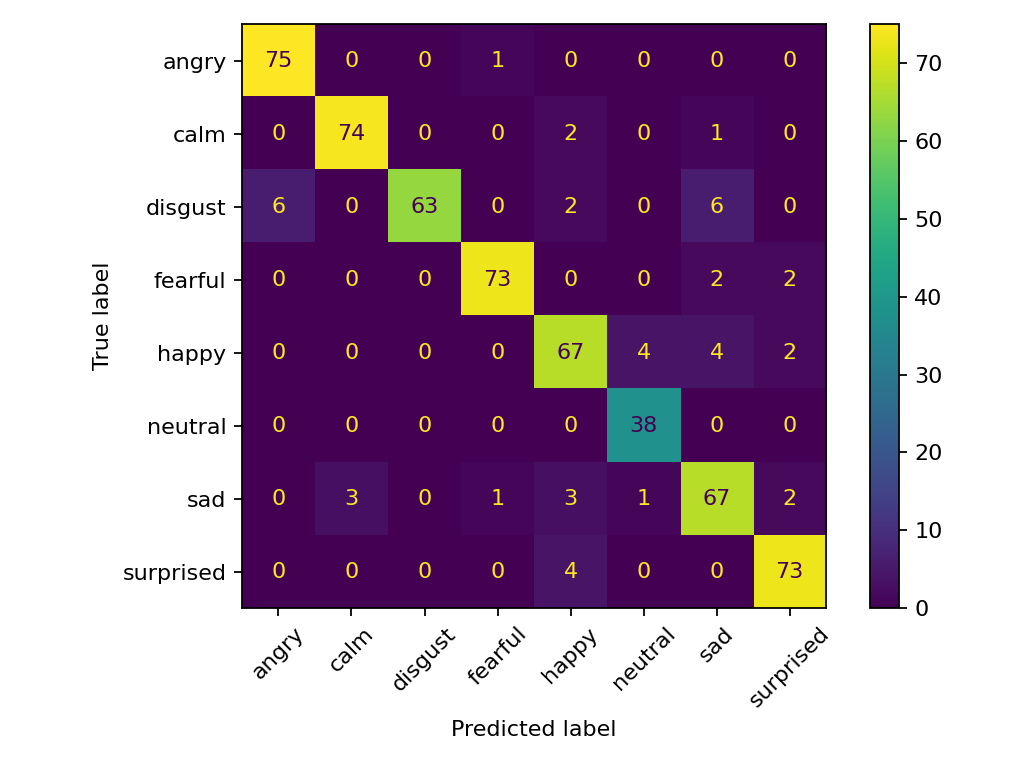

In [16]:
from IPython.display import Image

Image("reports/confusion_matrix.png")